---
---

<h1><center><ins>Exercise Sheet 5</ins></center></h1>
<h2><center>Numerical Methods <br>

---
---

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp, cos, sin, pi, sqrt

import matplotlib.pylab as pylab
params = {'legend.fontsize': 'xx-large',
          'figure.figsize': (12, 7),
         'axes.labelsize': 'xx-large',
         'axes.titlesize':'xx-large',
         'xtick.labelsize':'xx-large',
         'ytick.labelsize':'xx-large'}
pylab.rcParams.update(params)

## Exercise 1 - Numerical derivative

**(A)** Compute the derivative of the following two functions:

$$ f_1(x) = x^2 + \cos(x) $$

$$ f_2(x) = \exp(x) - x^3 $$

in correspondence of at least $N = 50$ values $x_i$ ($i = 1, ..., N$) of the variable $x$ in the interval $[1,5]$. To do this, *write your own code to compute the derivatives numerically*.

**(B)** Compare the resulting values you get for the numerical derivatives with the corresponding analytic solutions. Calculate the value of the quantity $q$ for each function:

$$ q = \sum_{i=1}^N \frac{\left[d_i - f'(x_i) \right]}{f'(x_i)} $$

where $d_i$ are the values you obtained for the numerical derivatives for each of the $N$ abscissas, and $f'(x_i)$ are the analytical derivatives evaluated in points $x_i$. How does the value of $q$ change when changing the value of $h$ to compute the derivatives numerically? How do the values of $q$ compare for the two functions? Discuss your findings.

In [3]:
def f1(x):
    return x**2 + cos(x)

def df1(x):
    return(2 * x - sin(x))

def f2(x):
    return exp(x) - x**3

def df2(x):
    return(exp(x) - 3 * x**2)

def deriv(f, a, b, N):
    dy = []
    dx = (b - a) / N
    x1 = a - dx/2
    y1 = f(x1)
    for i in range(N):
        x2 = a + (i + 0.5) * dx         # in this way we avoid a drift by incrementing small values
        y2 = f(x2)
        dy.append((y2 - y1) / dx)
        x1, y1 = x2, y2
    return np.array(dy)

In [4]:
def deriv_x_y(x, y):
    if len(x) < 2 or len(x) != len(y):
        raise ValueError('no good arguments')

    dy = []
    x1, y1 = x[0], y[0]
    x2, y2 = x[1], y[1]

    h = x2 - x1
    if h <= 0:
        raise ValueError('x not monotonically increasing!')

    dy.append((y2 - y1) / h)

    if len(x) == 2:
        return np.array([dy[0], dy[0]])

    for i in range(1, len(x) - 1):
        x3, y3 = x[i + 1], y[i + 1]

        h = x3 - x1
        if x3 <= x2:
            raise ValueError('x not monotonically increasing!')

        dy.append((y3 - y1) / h)

        x1, y1 = x2, y2
        x2, y2 = x3, y3

    h = x2 - x1
    dy.append((y2 - y1) / h)

    return np.array(dy)


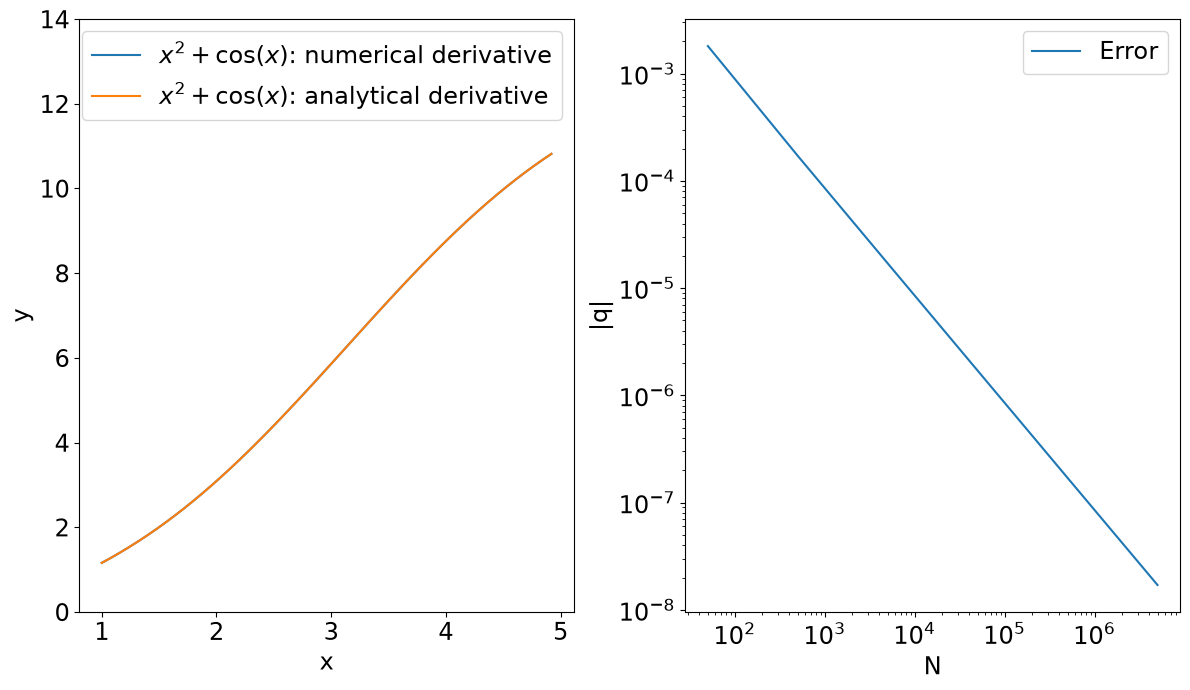

In [12]:
xs = np.linspace(1, 5, 50, endpoint=False)
df_num = deriv(f1, 1, 5, 50)
df_ana = df1(xs)

plt.figure()
plt.subplot(1, 2, 1)
plt.plot(xs, df_num, label=r'$x^2 + \cos(x)$: numerical derivative')
plt.plot(xs, df_ana, label=r'$x^2 + \cos(x)$: analytical derivative')
plt.ylim(0, 14)
plt.xlabel('x')
plt.ylabel('y')
plt.legend()

qs = []
qs_2 = []
Ns= [50, 500, 5000, 50_000, 500_000, 5_000_000]
for N in Ns:
    xs = np.linspace(1, 5, N, endpoint=False)
    df_num = deriv(f1, 1, 5, N)
    df_ana = df1(xs)
    q = ((df_num - df_ana)/df_ana).sum()
    qs.append(abs(q)) 

plt.subplot(1, 2, 2)
plt.plot(Ns, qs, label='Error')
plt.xlabel('N')
plt.ylabel('|q|')
plt.xscale('log')
plt.yscale('log')
plt.tight_layout()
plt.legend()
plt.show()

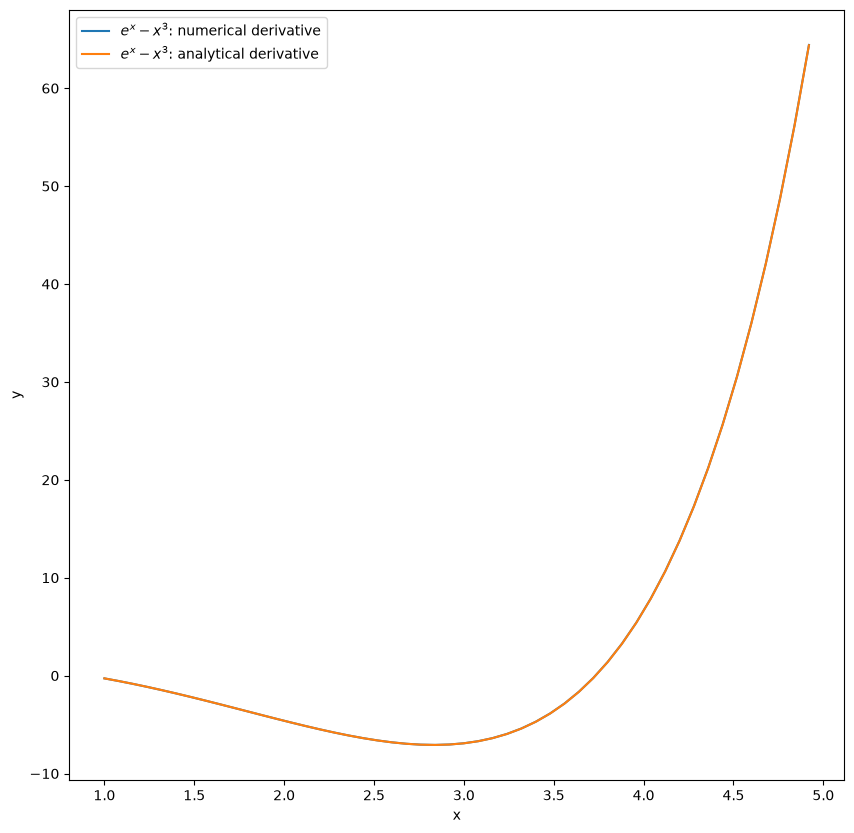

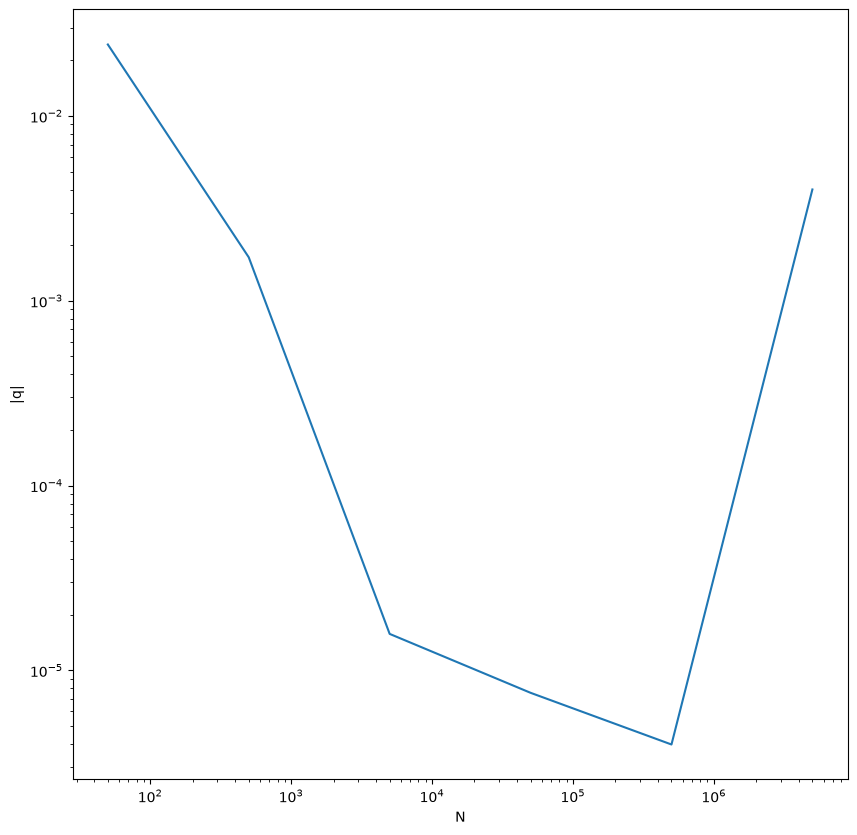

In [17]:
xs = np.linspace(1, 5, 50, endpoint=False)
df_num = deriv(f2, 1, 5, 50)
df_ana = df2(xs)

plt.figure(figsize=(10,10))
plt.plot(xs, df_num, label=r'$e^x - x^3$: numerical derivative')
plt.plot(xs, df_ana, label=r'$e^x - x^3$: analytical derivative')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show

qs = []
Ns= [50, 500, 5000, 50_000, 500_000, 5_000_000]
for N in Ns:
    xs = np.linspace(1, 5, N, endpoint=False)
    df_num = deriv(f2, 1, 5, N)
    df_ana = df2(xs)
    q = ((df_num - df_ana)/df_ana).sum()
    qs.append(abs(q)) 

plt.figure(figsize=(10, 10))
plt.plot(Ns, qs)
plt.xlabel('N')
plt.ylabel('|q|')
plt.xscale('log')
plt.yscale('log')
plt.show()

q is a measure of the quality. I plotted the absolute value, because I wanted to plot it logarithmic.
There is an obvious observation: increasing N improves the quality. However, things are more complicated, like usual.
First I learnt, that repeatedly incrementing x1 by dx becomes problematic for small dx, there is a drift, which deteriorates the quality
at high N. Replacing this with the x2 = a + (i + 0.5) * dx improved the quality for f1 for high N. q as a function of N now shows a straight line. Before, it showed a minimum at 500000 and then an 
increased error at 5.000.000.
However, f2 is behaving differently. There, the error is higher, because its derivative crosses 0 at around 3.73, the denominator can get close to zero, thus giving a high value for q. It is doubtful, that the q defined like this is really a good metric for the quality.

## Exercise 2 - Newton-Cotes formulas

In the file ```surface_luminosity.txt``` you will find the numerical function describing the surface luminosity $\Sigma$ of a globular star cluster as a function of the distance $R$ from its centre (projected on the plane of the sky). Compute the total luminosity $L$ of the system by performing the integral

$$ L = \int_0^{R_{\text{max}}} \Sigma(R) \, 2 \pi R \, dR $$

using the trapezoid rule and Simpson's rule, and compare the results you obtain. To do this, first choose one of these methods and implement **your own algorithm to compute the integral with it**; for the other method, use the corresponding built-in python function ```scipy.integrate.trapz``` or ```scipy.integrate.simps``` and familiarize on its usage.

In [18]:
from scipy import integrate

R, S = np.loadtxt('surface_luminosity.txt', skiprows=1, unpack=True)

def trapez(x, y):
    Int = 0.0
    x1, y1 = x[0], y[0]
    for i in range(1, len(x)):
        x2, y2 = x[i], y[i]
        Int += (x2 - x1) * (y1 + y2) / 2
        x1, y1 = x2, y2
    return Int

L = trapez(R, 2 * pi * R * S)
print(f'My Trapez rule result: {L:.0f}')

L_scipy_simp = integrate.simpson(2 * pi * R * S, x = R)
print(f'SciPy Simpson:         {L_scipy_simp:.0f}')
L_scipy_trap = integrate.trapezoid(2 * pi * R * S, x = R)
print(f'SciPy Trapezoid:       {L_scipy_trap:.0f}')

My Trapez rule result: 1285409
SciPy Simpson:         1282550
SciPy Trapezoid:       1285409


## Exercise 3 - Gaussian Quadrature

**(A)** Compute the following integral by using a 4-point Gaussian quadrature. 

$$ I = \int_{-1}^{1} \cos(x) dx $$

To do this, use the Legendre polynomial of degree 4:

$$ P_4(x) = \frac{1}{8}(35 x^4 - 30 x^2 +3) $$

At this link: https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature you can find the roots of Legendre polynomials and the necessary weights to solve the integral (i.e., you do not have to calculate them all from scratch!).

**(B)** Compare the result with the ones you obtain when using a Legendre polynomial of degree 3, 2, and 1, and comment your findings.

In [19]:
from numpy.polynomial.legendre import leggauss

x_i = dict()
w_i = dict()
x_i[1] = [0]
w_i[1] = [2]
x_i[2] = [1 / sqrt(3), -1 / sqrt(3)]
w_i[2] = [1, 1]
x_i[3] = [0, sqrt(3 / 5), - sqrt(3 / 5)]
w_i[3] = [8 / 9, 5 / 9, 5 / 9]
x_i[4] = [sqrt(3 / 7 - 2 / 7 * sqrt(6 / 5)), - sqrt(3 / 7 - 2 / 7 * sqrt(6 / 5)), sqrt(3 / 7 + 2 / 7 * sqrt(6 / 5)), - sqrt(3 / 7 + 2 / 7 * sqrt(6 / 5))]
w_i[4] = [(18 + sqrt(30)) / 36, (18 + sqrt(30)) / 36, (18 - sqrt(30)) / 36, (18 - sqrt(30)) / 36]
x_i[5] = [0, 1 / 3 * sqrt(5 - 2* sqrt(10 / 7)), - 1 / 3 * sqrt(5 - 2* sqrt(10 / 7)), 1 / 3 * sqrt(5 + 2* sqrt(10 / 7)), - 1 / 3 * sqrt(5 + 2* sqrt(10 / 7))]
w_i[5] = [128 / 225, (322 + 13 * sqrt(70)) / 900, (322 + 13 * sqrt(70)) / 900, (322 - 13 * sqrt(70)) / 900, (322 - 13 * sqrt(70)) / 900]

def gauss_quad(f, deg):
    global x_i, w_i
    deg = int(deg)
    if deg < 1 or deg > 5:
        raise ValueError('Degree outside 1..5')
    Int = 0
    for x, w in zip(x_i[deg], w_i[deg]):
        Int += w * f(x)
    return Int

def gauss_quad_2(f, deg):
    deg = int(deg)
    if deg < 1:
        raise ValueError('Degree outside 1..')
    x_i, w_i = leggauss(deg)
    Int = 0
    for x, w in zip(x_i, w_i):
        Int += w * f(x)
    return Int

for deg in [1, 2, 3, 4, 5]:
    print(f'Gaussian quadrature with Legendre polynome of degree {deg} for cosine: {gauss_quad(cos, deg)}')

print(f'Analytical result for integral of cos:                             {2 * sin(1)}')

Gaussian quadrature with Legendre polynome of degree 1 for cosine: 2.0
Gaussian quadrature with Legendre polynome of degree 2 for cosine: 1.6758236553899861
Gaussian quadrature with Legendre polynome of degree 3 for cosine: 1.683003547726917
Gaussian quadrature with Legendre polynome of degree 4 for cosine: 1.6829416886959736
Gaussian quadrature with Legendre polynome of degree 5 for cosine: 1.682941970407192
Analytical result for integral of cos:                             1.682941969615793


The Gaussian quadrature converges rather fast for this problem. Already for degree 2 we have 3 significant digits, and every degree adds about two more digits. At degree 5 we have already 10 correct digits.

## Exercise 4 - Monte Carlo integration 

Consider the following integral:
$$ I = \int_0^1 \cos \left(\frac{\pi x}{2} \right) dx = \frac{2}{\pi} $$

**(A)** Compute the above integral and its variance by using the following Monte Carlo methods:

1. mean value

How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.



Points: 10, Integral: 0.49464000616324055, var: 0.0036394257028719724, MC/True: 0.7769787047670232
Points: 30, Integral: 0.621099322138705, var: 0.0032249218166164723, MC/True: 0.975620533790278
Points: 100, Integral: 0.6350887682004944, var: 0.0010367400960776042, MC/True: 0.9975951042780321
Points: 300, Integral: 0.6303861526413663, var: 0.0003316677428440268, MC/True: 0.9902082530314252
Points: 1000, Integral: 0.6368183233561806, var: 9.08986355735047e-05, MC/True: 1.0003118831635731
Points: 3000, Integral: 0.6322087908690797, var: 3.200568764729836e-05, MC/True: 0.9930712464645932
Points: 10000, Integral: 0.6398120831869933, var: 9.452140903375148e-06, MC/True: 1.00501447010912
Points: 30000, Integral: 0.6364435668804417, var: 3.131503246742358e-06, MC/True: 0.9997232170680399
Points: 100000, Integral: 0.6393227306718124, var: 9.446650116659342e-07, MC/True: 1.0042457969757659
Points: 300000, Integral: 0.6373309840976475, var: 3.14849916068397e-07, MC/True: 1.0011171687731615
Point

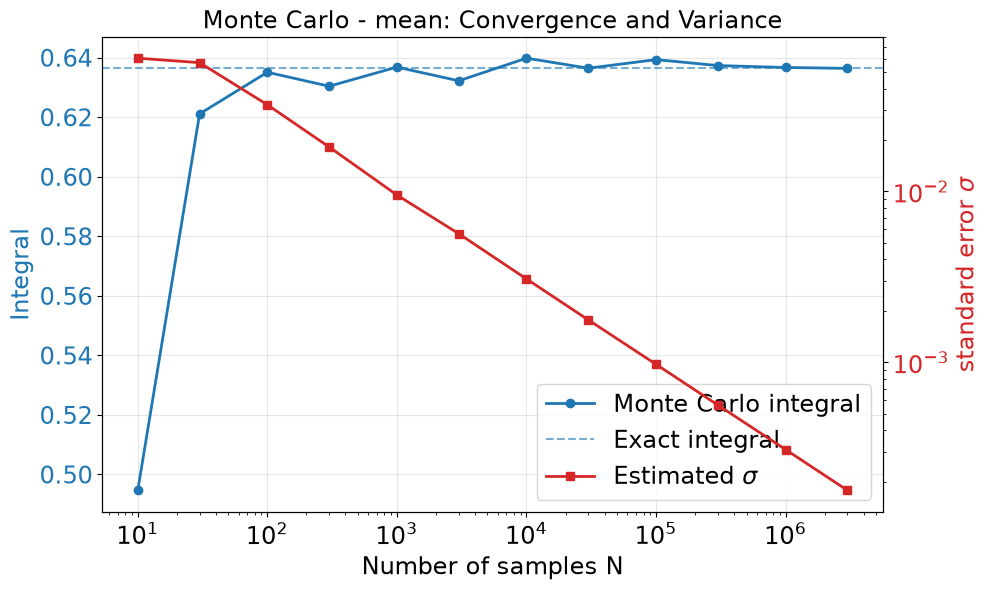

In [24]:
def Monte_Carlo_mean(f, a, b, N):
    x = np.random.uniform(a, b, N)
    y = f(x)
    y_mean = y.mean()
    I = (b - a) * y_mean
    var = (b - a)**2 / N * np.var(y, mean=y_mean)
    return I, var

Ns = [10, 30, 100, 300, 1000, 3000, 10_000, 30_000, 100_000, 300_000, 1_000_000, 3_000_000]
Is = []
vars = []
for N in Ns:
    I, var = Monte_Carlo_mean(lambda x: cos(pi * x / 2), 0, 1, N)
    print(f'Points: {N}, Integral: {I}, var: {var}, MC/True: {I / (2 / pi)}')
    Is.append(I)
    vars.append(sqrt(var))

fig, ax1 = plt.subplots(figsize=(10, 6))

# Integral (left axis)
ax1.plot(Ns, Is, 'o-', color='tab:blue',
         label='Monte Carlo integral', linewidth=2)
ax1.axhline(2 / pi, color='tab:blue', linestyle='--',
            alpha=0.6, label='Exact integral')

ax1.set_xlabel('Number of samples N')
ax1.set_ylabel('Integral', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_xscale('log')
ax1.grid(True, alpha=0.3)

# Variance (right axis)
ax2 = ax1.twinx()
ax2.plot(Ns, vars, 's-', color='tab:red',
         label=r'Estimated $\sigma$', linewidth=2)

ax2.set_ylabel(r'standard error $\sigma$', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')
ax2.set_yscale('log')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='best')

plt.title('Monte Carlo - mean: Convergence and Variance')
plt.tight_layout()
plt.show()


## Exercise 5 - Monte Carlo integration continued (optional)

**(A)** Compute the above integral from Exercise 4 and its variance by using the other Monte Carlo methods covered in the lecture:

2. Importance sampling

Hint: for importance sampling, you can use the following weight function: 
$$w(x) = A \frac{1}{1+\left( \pi x/2 \right)^2}$$
where you can determine the normalization constant by imposing:
$$\int_0^1 w(x) dx = 1 = A \frac{2}{\pi} \arctan(\pi/2) \rightarrow A = \frac{\pi}{2 \arctan(\pi/2)}$$


How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.

In [25]:
A = np.pi / (2 * np.arctan(np.pi / 2))

def w(x):
    return A / (1 + (np.pi * x / 2)**2)

def sample(N):
    u = np.random.uniform(0, 1, N)
    return 2 / np.pi * np.tan(u * np.arctan(np.pi / 2))

def Monte_Carlo_importance(f, N):
    x = sample(N)
    y = f(x) / w(x)

    I = y.mean()
    var = np.var(y, mean=I)
    var /= N

    return I, var

Points: 10, Integral: 0.6657358939109932, var: 0.0010965664631463223, MC/True: 1.045735496770905
Points: 30, Integral: 0.6093683384570103, var: 0.0008854168626082799, MC/True: 0.957193547713381
Points: 100, Integral: 0.6034488407933039, var: 0.0003295114038093189, MC/True: 0.94789522252676
Points: 300, Integral: 0.6387261491553454, var: 5.3536437808517945e-05, MC/True: 1.0033086889210658
Points: 1000, Integral: 0.6396836120544626, var: 1.484505509396383e-05, MC/True: 1.0048126681260414
Points: 3000, Integral: 0.6342472547498348, var: 6.091573963507198e-06, MC/True: 0.9962732580407875
Points: 10000, Integral: 0.6343141095145017, var: 1.8078519772526965e-06, MC/True: 0.9963782732595551
Points: 30000, Integral: 0.637264666920832, var: 5.669692650631299e-07, MC/True: 1.001012997995416
Points: 100000, Integral: 0.6370249893617753, var: 1.7251743445852971e-07, MC/True: 1.0006365133660347
Points: 300000, Integral: 0.6367852363129638, var: 5.726039549397082e-08, MC/True: 1.0002599101576237
Poi

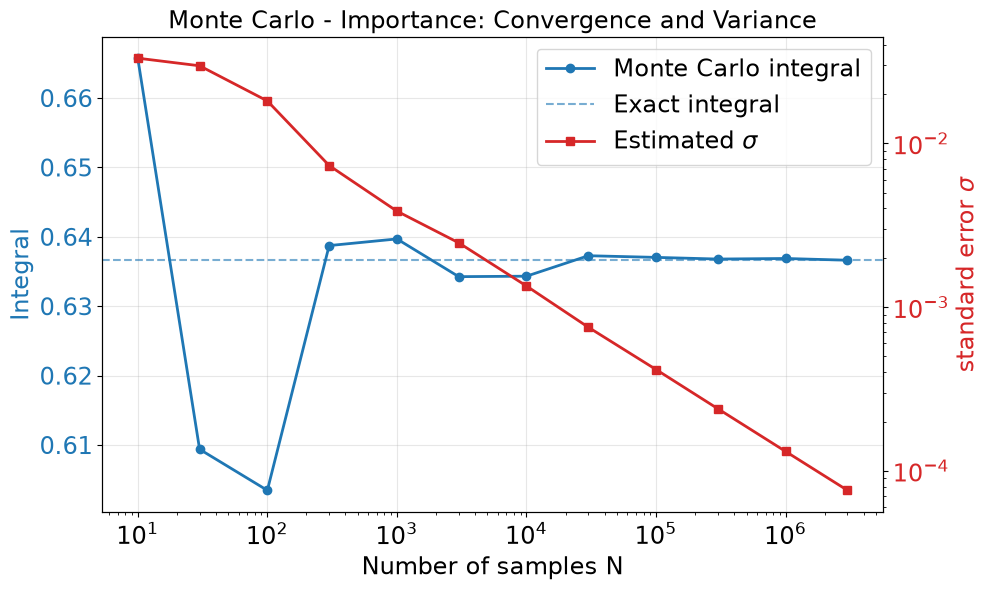

In [26]:
Ns = [10, 30, 100, 300, 1000, 3000, 10_000, 30_000, 100_000, 300_000, 1_000_000, 3_000_000]
Is = []
vars = []
for N in Ns:
    I, var = Monte_Carlo_importance(lambda x: cos(pi * x / 2), N)
    print(f'Points: {N}, Integral: {I}, var: {var}, MC/True: {I / (2 / pi)}')
    Is.append(I)
    vars.append(sqrt(var))

fig, ax1 = plt.subplots(figsize=(10, 6))

# Integral (left axis)
ax1.plot(Ns, Is, 'o-', color='tab:blue',
         label='Monte Carlo integral', linewidth=2)
ax1.axhline(2 / pi, color='tab:blue', linestyle='--',
            alpha=0.6, label='Exact integral')

ax1.set_xlabel('Number of samples N')
ax1.set_ylabel('Integral', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_xscale('log')
ax1.grid(True, alpha=0.3)

# Variance (right axis)
ax2 = ax1.twinx()
ax2.plot(Ns, vars, 's-', color='tab:red',
         label=r'Estimated $\sigma$', linewidth=2)

ax2.set_ylabel(r'standard error $\sigma$', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')
ax2.set_yscale('log')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='best')

plt.title('Monte Carlo - Importance: Convergence and Variance')
plt.tight_layout()
plt.show()